# Spectrogram-Based CNN With Attention for Deepfake Audio Detection in Podcast Production

**APCV 485 | Final Research Project**  
*Brian Stever (24042080)*  
GitHub repo: https://github.com/brianstever/APCV485_Final_Project_Stever

This notebook loads the final result files from my project and shows the main metrics, plots, and checks I used for the report.


## Why I Picked This Topic

I work in podcast production, so I wanted this project to connect the course material to something I actually deal with. A host's voice is part of their identity and reputation, and public podcast episodes give attackers a lot of clean voice data to work with.

That made deepfake audio detection feel like a useful cybersecurity problem to study, even though the setting is media production instead of a more traditional network or malware environment.


## Course Connection

The project connects to the class in a few direct ways:

- CNN architecture with an attention block.
- Detection metrics like EER, AUC, F1, and confusion matrices.
- A realistic distribution-shift problem between clean training data and harder evaluation data.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = PROJECT_ROOT / "results"
FIGURES = RESULTS / "figures"
METRICS = RESULTS / "metrics"
REPORT = PROJECT_ROOT / "report" / "Stever_Report.pdf"
PRESENTATION = PROJECT_ROOT / "presentation" / "Stever_Presentation.pdf"

print("Project root:", PROJECT_ROOT)
print("Results folder exists:", RESULTS.exists())
print("Report exists:", REPORT.exists())
print("Presentation PDF exists:", PRESENTATION.exists())


Project root: /Users/brianstever/University of Arizona/Spring 2026/APCV 485/Final Project/submission/APCV485_Final_Project_Stever
Results folder exists: True
Report exists: True
Presentation PDF exists: True


## Project Setup

The setup I used was:

1. Train on ASVspoof 2019 LA train.
2. Tune on ASVspoof 2019 LA dev.
3. Evaluate on ASVspoof 2021 LA eval.
4. Convert audio to 16 kHz mono, 4-second clips, and 128-bin log-Mel spectrograms.
5. Compare CNN + SE against ResNet-18 and LFCC-GMM.
6. Add podcast-style stress testing with noise, reverb, and MP3 compression.

I ran this locally on my MacBook using Apple Silicon MPS. The latency number is useful for my setup, but I would not treat it as a hardware comparison.


In [2]:
study_setup_alignment = pd.DataFrame([
    {"project item": "2019 LA train/dev", "final status": "completed", "evidence": "25,380 train clips and 24,844 dev clips"},
    {"project item": "2021 LA eval", "final status": "completed", "evidence": "181,566 evaluation clips"},
    {"project item": "CNN + SE model", "final status": "completed", "evidence": "models/best_model.pt"},
    {"project item": "ResNet-18 baseline", "final status": "completed", "evidence": "results/metrics/resnet18_metrics.json"},
    {"project item": "LFCC-GMM baseline", "final status": "completed", "evidence": "results/metrics/lfcc_gmm_metrics.json"},
    {"project item": "podcast-style stress test", "final status": "completed", "evidence": "results/metrics/cnn_se_podcast_stress_metrics.json"},
    {"project item": "local runtime check", "final status": "completed locally", "evidence": "1.66 ms on my MacBook using Apple Silicon MPS"},
])
study_setup_alignment


,project item,final status,evidence
0,2019 LA train/dev,completed,"25,380 train clips and 24,844 dev clips"
1,2021 LA eval,completed,"181,566 evaluation clips"
2,CNN + SE model,completed,models/best_model.pt
3,ResNet-18 baseline,completed,results/metrics/resnet18_metrics.json
4,LFCC-GMM baseline,completed,results/metrics/lfcc_gmm_metrics.json
5,podcast-style stress test,completed,results/metrics/cnn_se_podcast_stress_metrics....
6,local runtime check,completed locally,1.66 ms on my MacBook using Apple Silicon MPS


## Dataset Counts

These are the full ASVspoof splits I used for training, tuning, and evaluation.


In [3]:
dataset_counts = pd.DataFrame([
    {"split": "ASVspoof 2019 LA train", "bonafide": 2580, "spoof": 22800, "total": 25380},
    {"split": "ASVspoof 2019 LA dev", "bonafide": 2548, "spoof": 22296, "total": 24844},
    {"split": "ASVspoof 2021 LA eval", "bonafide": 18452, "spoof": 163114, "total": 181566},
])
dataset_counts


,split,bonafide,spoof,total
0,ASVspoof 2019 LA train,2580,22800,25380
1,ASVspoof 2019 LA dev,2548,22296,24844
2,ASVspoof 2021 LA eval,18452,163114,181566


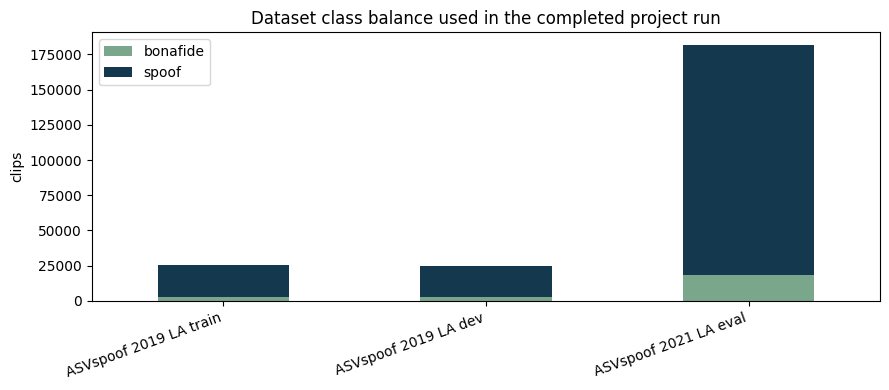

In [4]:
ax = dataset_counts.set_index("split")[["bonafide", "spoof"]].plot(
    kind="bar", stacked=True, figsize=(9, 4), color=["#7aa68b", "#14394f"]
)
ax.set_title("Dataset class balance used in the completed project run")
ax.set_ylabel("clips")
ax.set_xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## Spectrogram Input

The model does not listen to the audio like a person would. Each clip becomes a log-Mel spectrogram, so the CNN sees the audio as a time-frequency image.


results/figures/sample_spectrogram.png


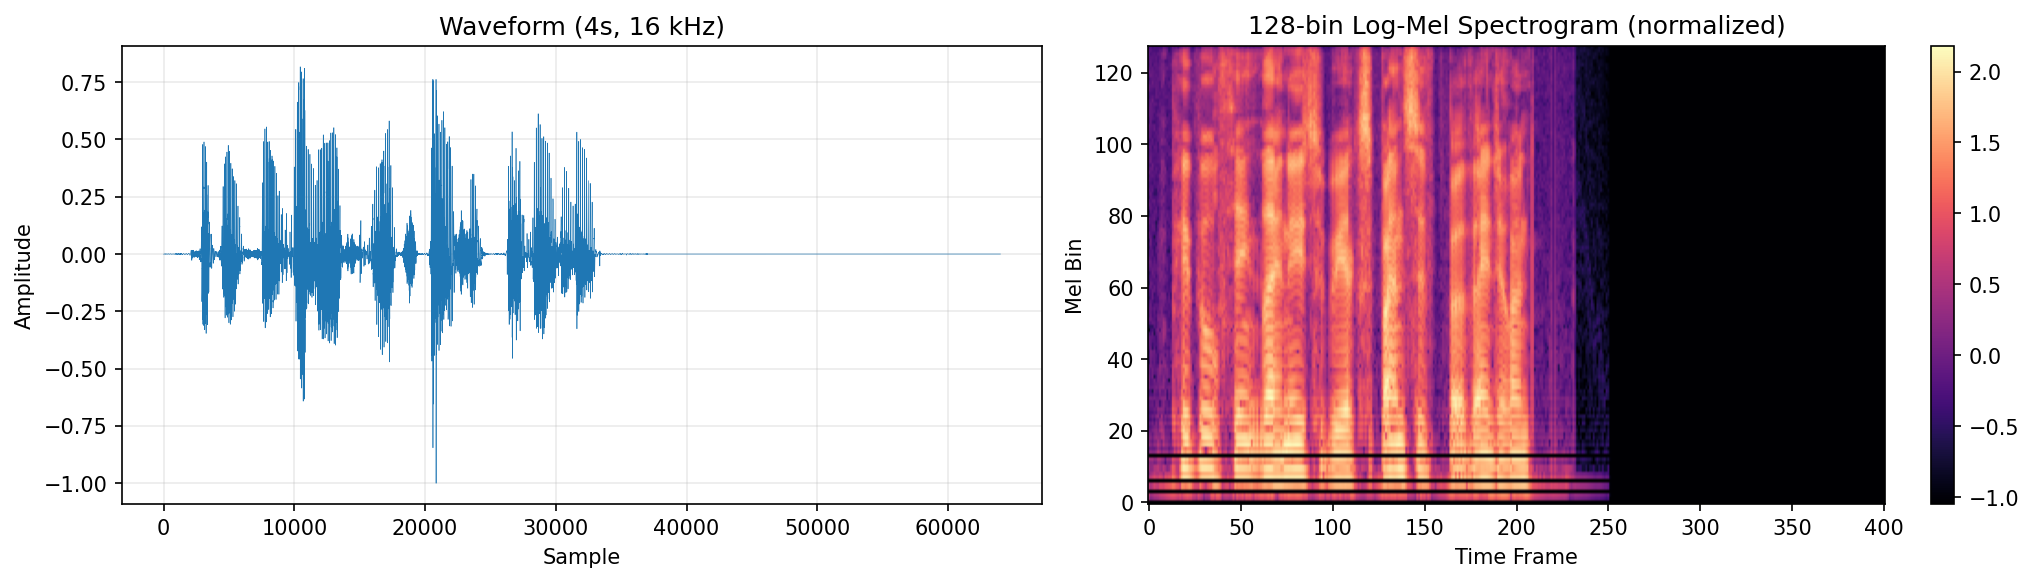

results/figures/augmentation_comparison.png


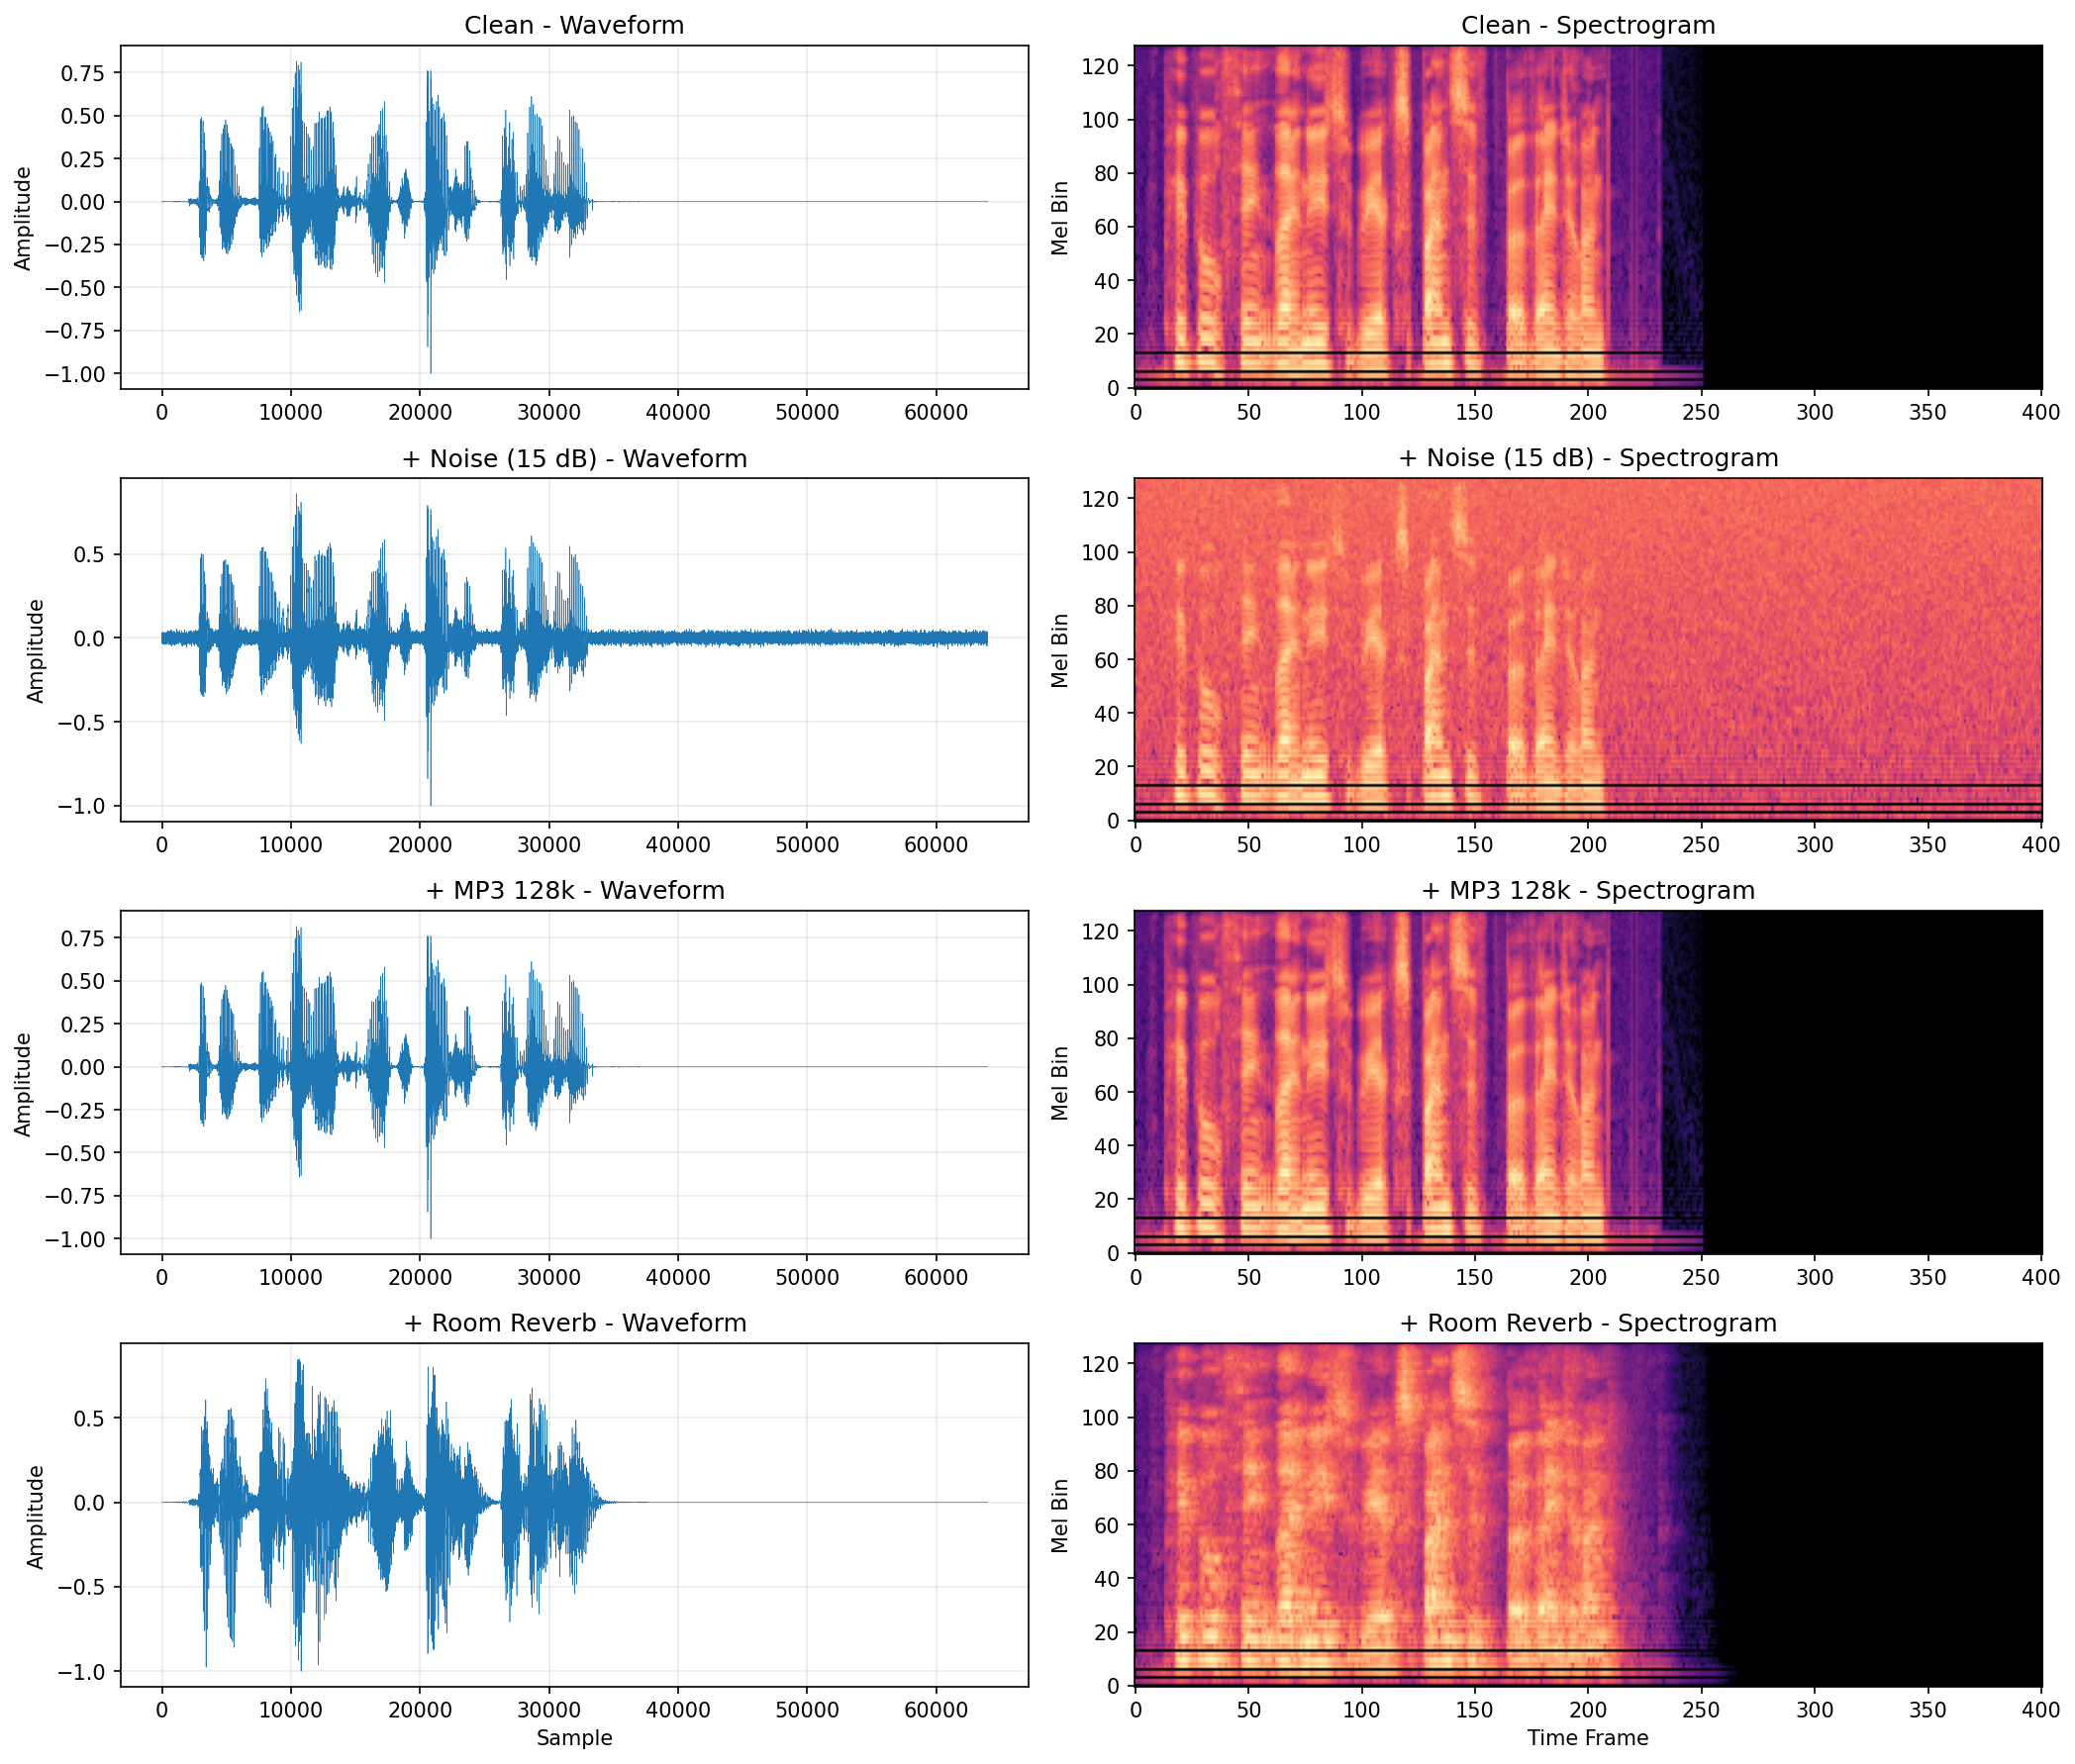

In [5]:
for image_path in [
    FIGURES / "sample_spectrogram.png",
    FIGURES / "augmentation_comparison.png",
]:
    print(image_path.relative_to(PROJECT_ROOT))
    display(Image(filename=str(image_path)))


## Model And Baselines

The main model was a CNN with Squeeze-and-Excitation attention. I used it because it was a reasonable middle ground: more capable than a basic CNN, but not as heavy as a large pretrained audio model.

I also included two baselines:

- ResNet-18 on the same spectrogram setup.
- LFCC-GMM as a traditional spoofing baseline.


In [6]:
model_summary = pd.DataFrame([
    {"model": "CNN + SE", "parameters": "1.31M", "role": "main model"},
    {"model": "ResNet-18", "parameters": "11.17M", "role": "deep learning baseline"},
    {"model": "LFCC-GMM", "parameters": "n/a", "role": "traditional signal-processing baseline"},
])
model_summary


,model,parameters,role
0,CNN + SE,1.31M,main model
1,ResNet-18,11.17M,deep learning baseline
2,LFCC-GMM,n/a,traditional signal-processing baseline


## Final Metrics

I used EER as the main metric because this is a spoofing detection problem. I also tracked AUC, accuracy, precision, recall, F1, and latency so I was not relying on one number only.


In [7]:
metrics_path = METRICS / "metrics_summary_full_run.csv"
metrics = pd.read_csv(metrics_path)
metrics[["experiment", "n_samples", "eer", "auc_roc", "accuracy", "precision", "recall", "f1_score", "latency_ms_per_clip"]]


,experiment,n_samples,eer,auc_roc,accuracy,precision,recall,f1_score,latency_ms_per_clip
0,CNN + SE clean 2021 LA,181566,0.182802,0.897907,0.907158,0.956691,0.939171,0.947850,1.662871
1,CNN + SE podcast stress 2021 LA,181566,0.184840,0.885219,0.899056,0.956370,0.930067,0.943035,1.566620
2,ResNet-18 clean 2021 LA,181566,0.172111,0.895745,0.854863,0.971626,0.863666,0.914470,2.225720
3,LFCC-GMM clean 2021 LA,181566,0.308863,0.740010,0.706289,0.950578,0.709976,0.812846,NaN
4,CNN + SE cross-vocoder A05/A06 dev,9980,0.050677,0.988063,0.413126,0.996219,0.212729,0.350593,1.662151


In [8]:
shown = metrics[["experiment", "eer", "auc_roc", "accuracy", "precision", "recall", "f1_score", "latency_ms_per_clip"]].copy()
for col in ["eer", "auc_roc", "accuracy", "precision", "recall", "f1_score"]:
    shown[col] = shown[col].map(lambda x: f"{x:.4f}" if pd.notna(x) else "")
shown["latency_ms_per_clip"] = shown["latency_ms_per_clip"].map(lambda x: f"{x:.2f} ms" if pd.notna(x) else "")
shown


,experiment,eer,auc_roc,accuracy,precision,recall,f1_score,latency_ms_per_clip
0,CNN + SE clean 2021 LA,0.1828,0.8979,0.9072,0.9567,0.9392,0.9479,1.66 ms
1,CNN + SE podcast stress 2021 LA,0.1848,0.8852,0.8991,0.9564,0.9301,0.9430,1.57 ms
2,ResNet-18 clean 2021 LA,0.1721,0.8957,0.8549,0.9716,0.8637,0.9145,2.23 ms
3,LFCC-GMM clean 2021 LA,0.3089,0.7400,0.7063,0.9506,0.7100,0.8128,
4,CNN + SE cross-vocoder A05/A06 dev,0.0507,0.9881,0.4131,0.9962,0.2127,0.3506,1.66 ms


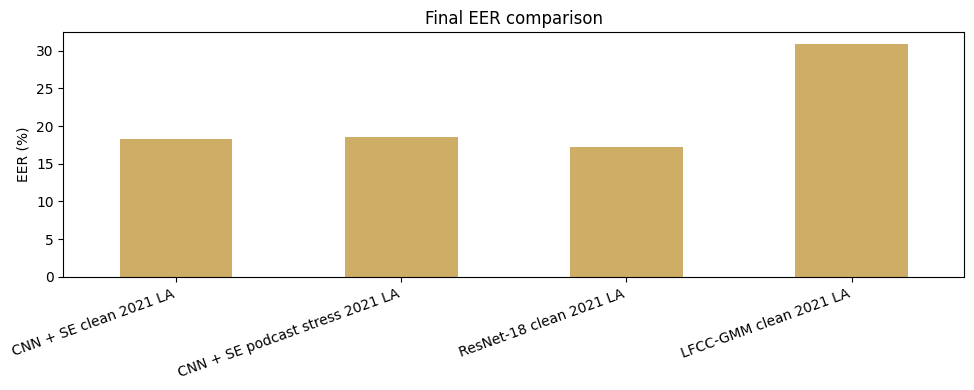

In [9]:
plot_df = metrics[metrics["experiment"].str.contains("2021 LA|LFCC-GMM", regex=True)].copy()
plot_df["EER (%)"] = plot_df["eer"] * 100
ax = plot_df.plot(x="experiment", y="EER (%)", kind="bar", legend=False, figsize=(10, 4), color="#ceaE66")
ax.set_title("Final EER comparison")
ax.set_xlabel("")
ax.set_ylabel("EER (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## What I Learned From The Results

The CNN + SE model worked as a real detector, but it did not hit the below-5% EER goal on full ASVspoof 2021 LA. The clean 2021 LA result was 18.28% EER, and the podcast-stress result was close at 18.48% EER.

ResNet-18 had the best EER at 17.21%, so I do not claim the attention model won outright. My read is that CNN + SE was competitive while being much smaller and faster. LFCC-GMM was weaker at 30.89% EER, which showed why the learned spectrogram models were useful.

The cross-vocoder check reached 5.07% EER on A05/A06 held-out spoofing algorithms, but fixed-threshold F1 was weak. That showed me that EER and AUC can look strong while the default 0.5 threshold is still not calibrated well enough.


## Key Figures

Main plots from the CNN + SE run.


results/figures/cnn_se_training_history.png


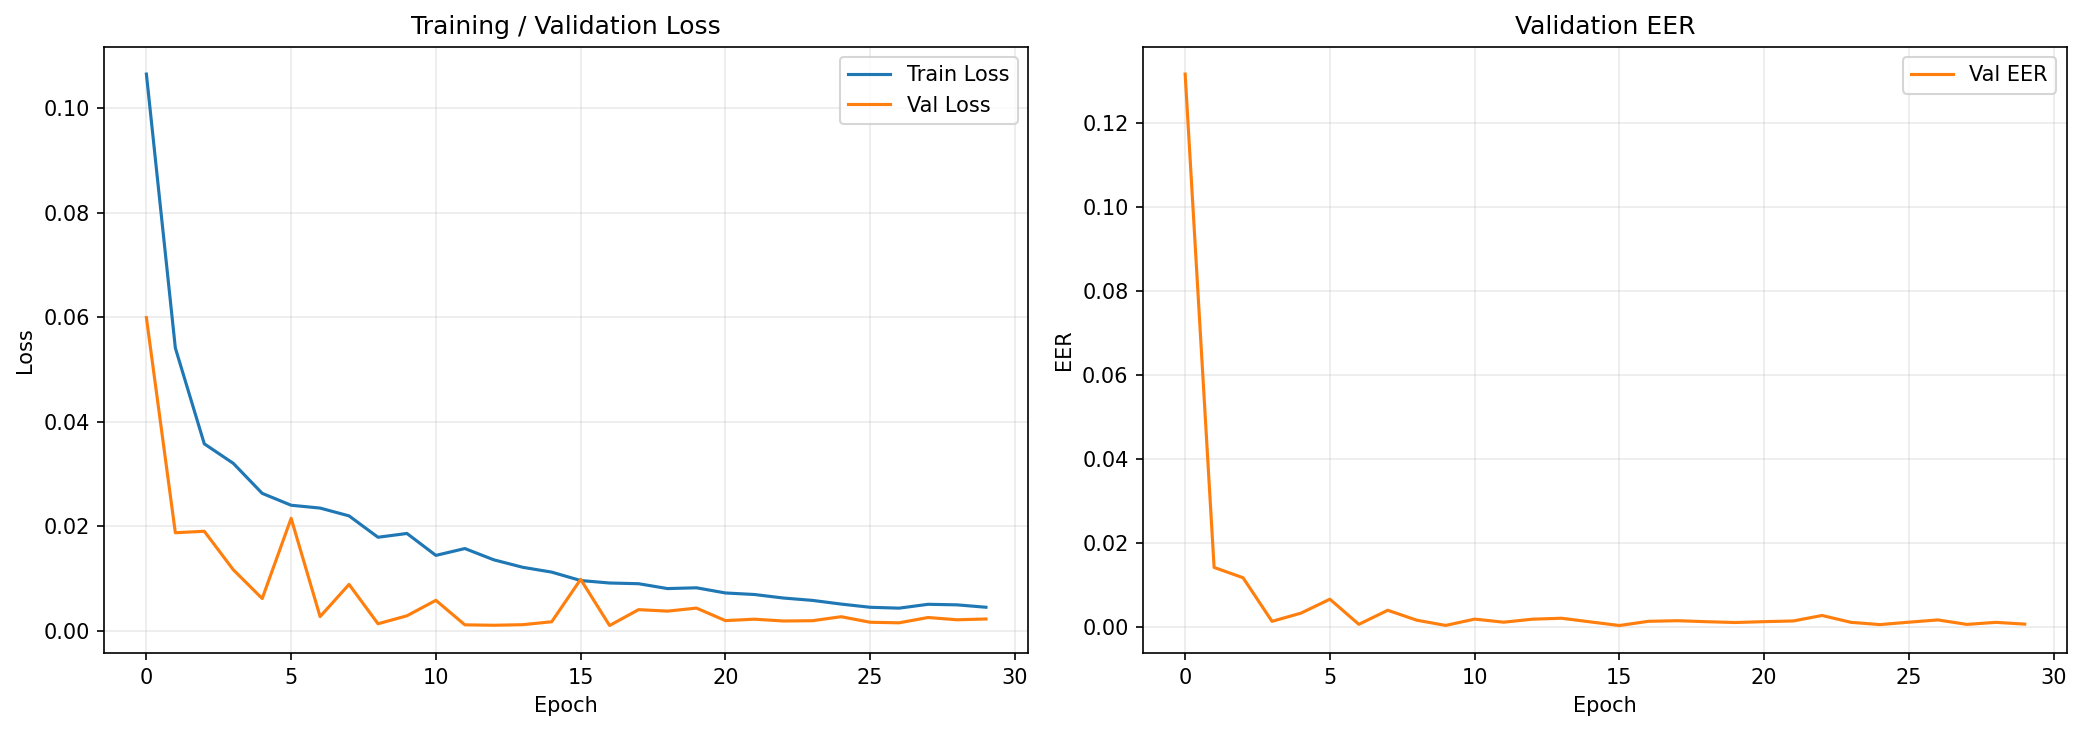

results/figures/cnn_se_roc_curve.png


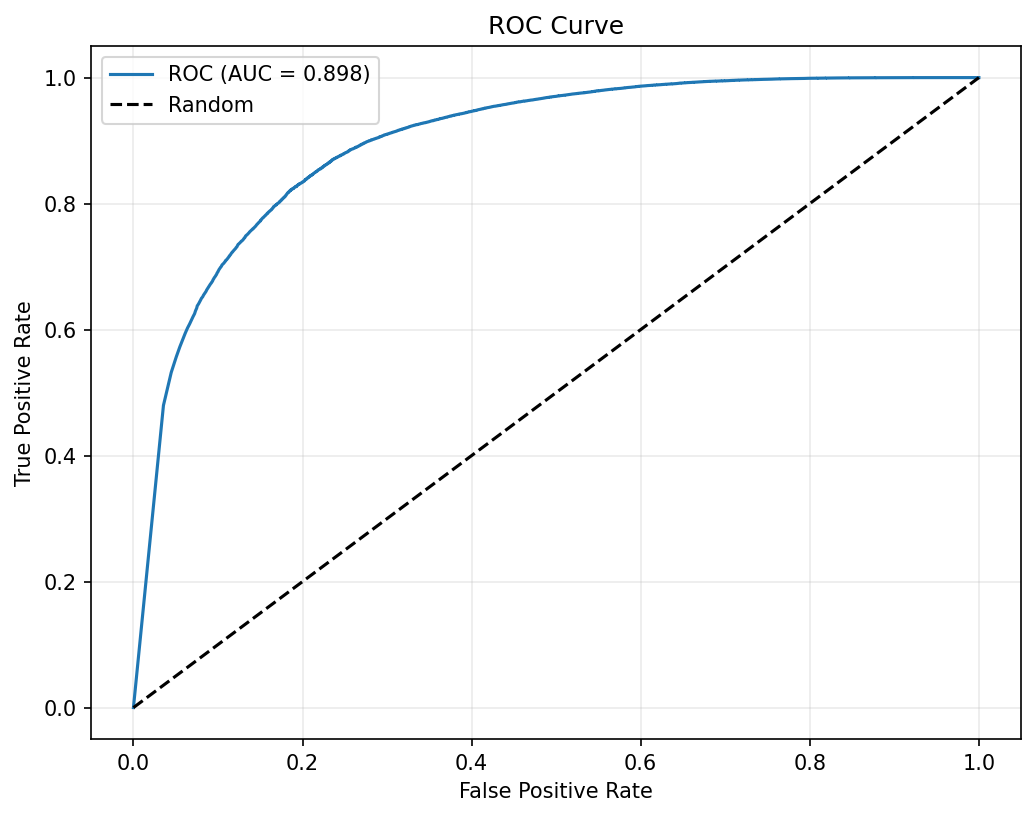

results/figures/cnn_se_confusion_matrix.png


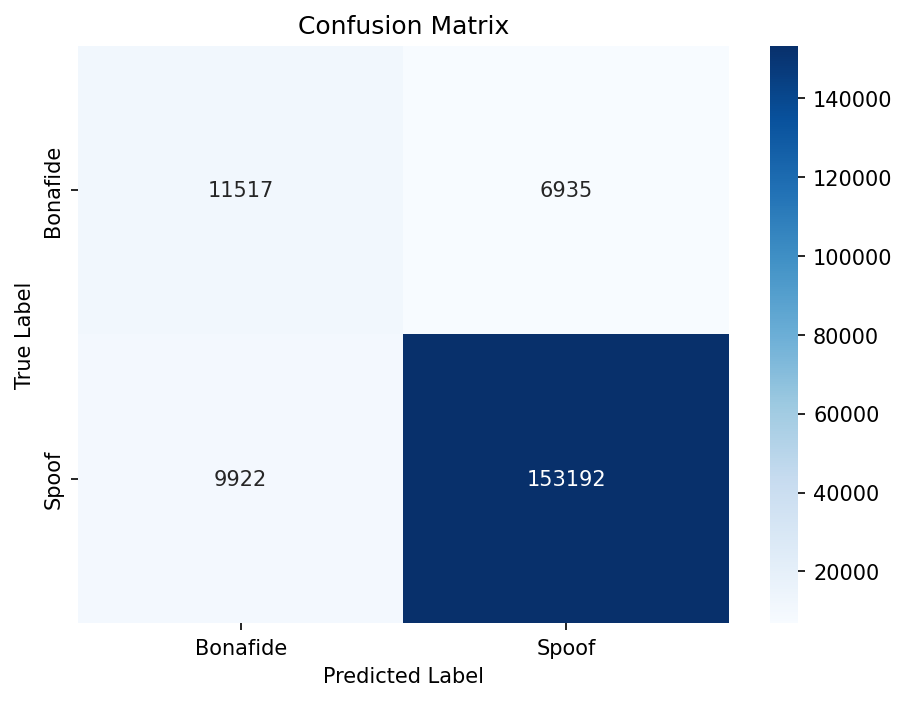

results/figures/cnn_se_score_distribution.png


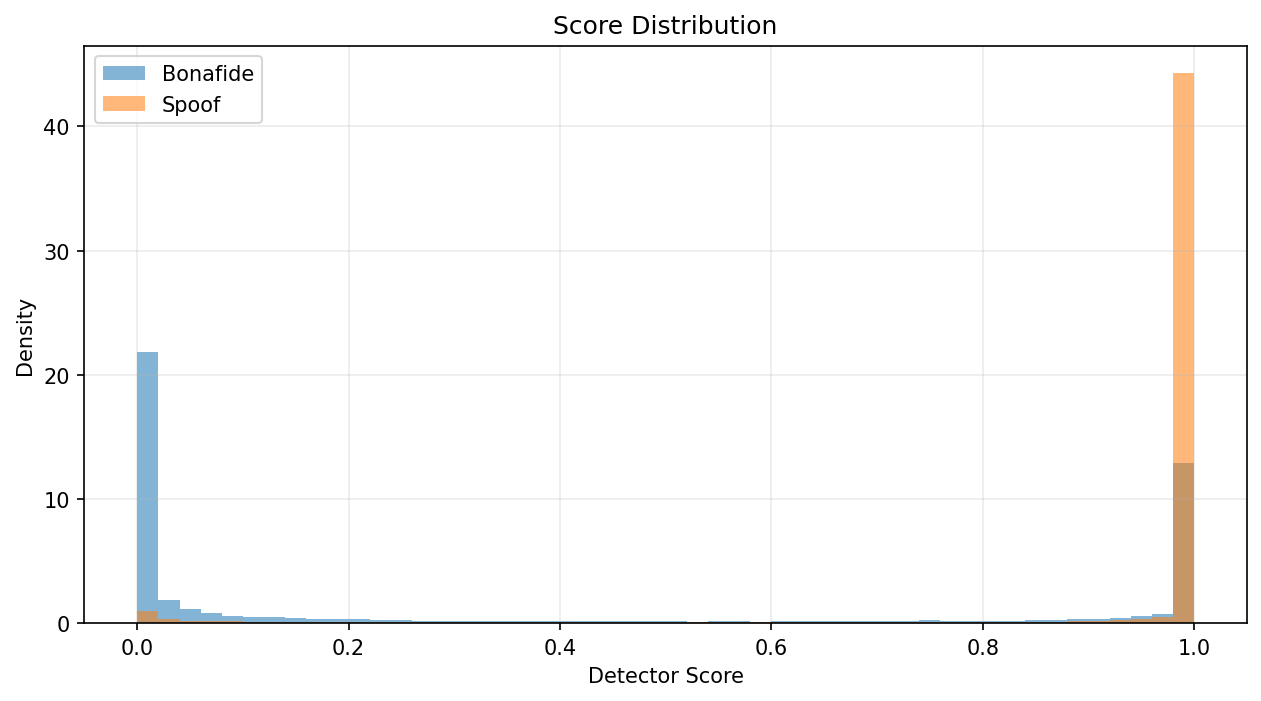

In [10]:
for image_path in [
    FIGURES / "cnn_se_training_history.png",
    FIGURES / "cnn_se_roc_curve.png",
    FIGURES / "cnn_se_confusion_matrix.png",
    FIGURES / "cnn_se_score_distribution.png",
]:
    print(image_path.relative_to(PROJECT_ROOT))
    display(Image(filename=str(image_path)))


## Limitations

This project is complete, but it is not something I would trust in a real publishing workflow yet.

- I did not meet the below-5% clean EER goal on full 2021 LA.
- Podcast augmentation did not change EER much, but AUC dropped.
- The cross-vocoder result showed that threshold calibration matters.
- Latency was measured locally on my MacBook using Apple Silicon MPS.
- Real podcast export chains still need to be tested directly from DAWs/platforms.


In [11]:
required = [
    REPORT,
    PRESENTATION,
    PROJECT_ROOT / "README.md",
    PROJECT_ROOT / "requirements.txt",
    METRICS / "metrics_summary_full_run.csv",
    METRICS / "cnn_se_metrics.json",
    METRICS / "resnet18_metrics.json",
    METRICS / "lfcc_gmm_metrics.json",
    METRICS / "cross_vocoder_metrics.json",
]

for path in required:
    status = "OK" if path.exists() else "MISSING"
    print(f"{status:7} {path.relative_to(PROJECT_ROOT)}")


OK      report/Stever_Report.pdf
OK      presentation/Stever_Presentation.pdf
OK      README.md
OK      requirements.txt
OK      results/metrics/metrics_summary_full_run.csv
OK      results/metrics/cnn_se_metrics.json
OK      results/metrics/resnet18_metrics.json
OK      results/metrics/lfcc_gmm_metrics.json
OK      results/metrics/cross_vocoder_metrics.json


## Final Reflection

The main value of this project was applying deep learning and cybersecurity to a part of my own work. Podcast production depends on trust, identity, files, platforms, and publishing workflows, so deepfake audio fits the cyber side more than I first expected.

The results were mixed, but that made the project more useful to me. I built and ran the real pipeline, and I also saw that full benchmark generalization is hard. Before this could be useful in an actual podcast workflow, I would need threshold calibration, stronger architectures, and real production-chain testing.
